In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import yfinance as yf
import datetime
import xgboost

from scipy.stats import norm
from scipy.integrate import quad
from scipy.optimize import minimize, least_squares, newton, differential_evolution, dual_annealing
from sklearn.model_selection import train_test_split
from sklearn.metrics import explained_variance_score, mean_absolute_percentage_error, mean_squared_error, mean_squared_log_error
from xgboost import XGBRegressor
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.metrics import r2_score
from joblib import Parallel, delayed
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
import torch
import torch.nn as nn
import torch.optim as optim
import random

Loading the Data

In [ ]:
# Load the created Stata files

path = "C:\\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\data_output_final\data_output_2003_top3_qual.dta"
data = pd.read_stata(path)
data = data.drop(["index"], axis = 1)


In [3]:
# data["cusip"].value_counts()
data = data[data["cusip"].isin(["64881510", "12486C10", "12490H10"])]
data.reset_index(drop=True, inplace=True) 
len(data)

166272

<function matplotlib.pyplot.show(close=None, block=None)>

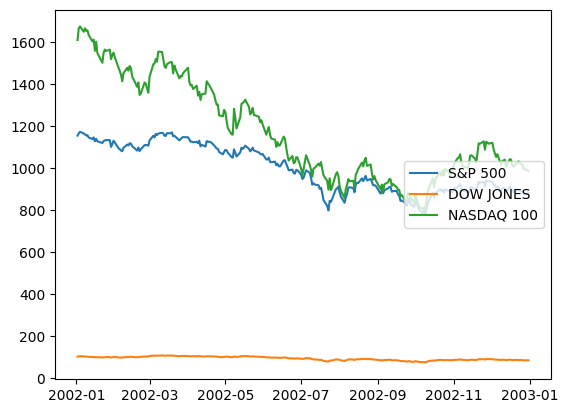

In [7]:
# min(data["stock_price"])
plt.plot(data[data["cusip"] == "64881510"]["date"], data[data["cusip"] == "64881510"]["stock_price"], label = 'S&P 500')
plt.plot(data[data["cusip"] == "12486C10"]["date"], data[data["cusip"] == "12486C10"]["stock_price"], label = 'DOW JONES')
plt.plot(data[data["cusip"] == "12490H10"]["date"], data[data["cusip"] == "12490H10"]["stock_price"], label = 'NASDAQ 100')
plt.legend(loc='right')
plt.show

In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [ ]:
# GPU-compatible Heston pricer
def heston_charf(phi, S0, V0, rf, lambd, tau, kappa, theta, sigma, rho):
    phi = phi.to(torch.complex64)

    a = kappa * theta
    b = kappa + lambd

    d = torch.sqrt((rho * sigma * phi * 1j - b)**2
        + sigma**2 * (phi**2 + 1j * phi) + 0j)

    g = (b - rho * sigma * phi * 1j - d) / (b - rho * sigma * phi * 1j + d)

    exp_dt = torch.exp(-d * tau)

    C = (
        rf * phi * 1j * tau
        + a / sigma**2 * (
            (b - rho * sigma * phi * 1j - d) * tau
            - 2 * torch.log((1 - g * exp_dt) / (1 - g))
        )
    )

    D = (
        (b - rho * sigma * phi * 1j - d) / sigma**2
        * (1 - exp_dt) / (1 - g * exp_dt)
    )

    log_cf = C + D * V0 + 1j * phi * torch.log(S0)

    log_cf = torch.clamp(log_cf.real, -100.0, 50.0) + 1j * log_cf.imag
    return torch.exp(log_cf)


def integrand(phi, S0, K, V0, rf, lambd, tau, kappa, theta, sigma, rho):
    arg = (S0, V0, rf, lambd, tau, kappa, theta, sigma, rho)

    phi = phi.to(torch.complex64)

    num = (
        torch.exp(rf * tau) * heston_charf(phi - 1j, *arg)
        - K * heston_charf(phi, *arg)
    )

    den = 1j * phi * K**(1j * phi)

    return num / den


    



_GL_N = 64
_gl_nodes_np, _gl_weights_np = np.polynomial.laguerre.laggauss(_GL_N)

def heston_price_gpu(S0, K, V0, rf, lambd, tau, kappa, theta, sigma, rho, n=128):
    
    batch_n = S0.shape[0]

    device = torch.device('cuda')
    S0 = torch.as_tensor(S0, device=device, dtype=torch.float64)
    K = torch.as_tensor(K, device=device, dtype=torch.float64)
    V0 = torch.as_tensor(V0, device=device, dtype=torch.float64)
    rf = torch.as_tensor(rf, device=device, dtype=torch.float64)
    lambd = torch.as_tensor(lambd, device=device, dtype=torch.float64)
    tau = torch.as_tensor(tau, device=device, dtype=torch.float64)
    kappa = torch.as_tensor(kappa, device=device, dtype=torch.float64)
    theta = torch.as_tensor(theta, device=device, dtype=torch.float64)
    sigma = torch.as_tensor(sigma, device=device, dtype=torch.float64)
    rho = torch.as_tensor(rho, device=device, dtype=torch.float64)

    args = (S0, K, V0, rf, lambd, tau, kappa, theta, sigma, rho)


    gl_x = torch.as_tensor(_gl_nodes_np, device=device, dtype=torch.float64)
    gl_w = torch.as_tensor(_gl_weights_np, device=device, dtype=torch.float64)
    gl_w_adj = gl_w * torch.exp(gl_x)

    phi_c = gl_x.to(torch.complex64)
    phi_grid = phi_c.unsqueeze(0).expand(batch_n, -1)

    args_batch = []
    for i in args:
        if i.ndim == 1:
            args_batch.append(i.unsqueeze(-1))
        else:
            args_batch.append(i.reshape(1,1).expand(batch_n, -1))

    vals = integrand(phi_grid, *args_batch)
    integral = torch.sum(vals * gl_w_adj.unsqueeze(0), dim=1)
    real_integral = torch.real(integral)
    call = (S0 - K * torch.exp(-rf * tau)) / 2.0 + real_integral / torch.pi

    return torch.maximum(call, torch.tensor(0.0, device=device))




def put_heston_gpu(call_price, S0, K, rf, tau):
    device = torch.device('cuda')
    S0 = torch.as_tensor(S0, device=device, dtype=torch.float64)
    K = torch.as_tensor(K, device=device, dtype=torch.float64)
    rf = torch.as_tensor(rf, device=device, dtype=torch.float64)
    tau = torch.as_tensor(tau, device=device, dtype=torch.float64)
    put = torch.exp(-rf*tau)*K + call_price - S0

    return torch.maximum(put, torch.tensor(0.0, device=device))



def heston_avg_var(V0, kappa, theta, tau):
    device = (torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu'))
    V0    = torch.as_tensor(V0.to_numpy(),    device=device, dtype=torch.float64)
    kappa = torch.as_tensor(kappa.to_numpy(), device=device, dtype=torch.float64)
    theta = torch.as_tensor(theta.to_numpy(), device=device, dtype=torch.float64)
    tau   = torch.as_tensor(tau.to_numpy(),   device=device, dtype=torch.float64)

    safe_kappa = kappa.clamp(min=1e-8)
    avg_var = theta + (V0 - theta) * (1.0 - torch.exp(-safe_kappa * tau)) / (safe_kappa * tau)
    return torch.sqrt(avg_var.clamp(min=0.0))


In [ ]:
def local_min_heston_with_batching_gpu(data, train_size=0.7, batch_size=2048, max_iter=50, verbose=True):

    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
    torch.set_default_dtype(torch.float64)


    X = data.drop(columns=["price"])
    Y = data["price"].astype(float)

    dates  = data["date"].sort_values().unique()
    cutoff = dates[int(len(dates) * train_size)]
    train_mask = data["date"] < cutoff
    X_train, X_test = X[train_mask], X[~train_mask]
    Y_train, Y_test = Y[train_mask], Y[~train_mask]

    x0 = {
        "V0": 0.1,
        "theta": 0.05,
        "sigma": 0.3,
        "rho": -0.5
    }
    bounds = {
        "V0": (1e-3, 0.3),
        "theta": (1e-3, 0.3),
        "sigma": (1e-2, 1.0),
        "rho": (-0.999, 0.0)
    }

    class HestonParamsBounded(nn.Module):
        def __init__(self, x0, bounds, device):
            super().__init__()
            self.device = device
            def inverse_map_sp(x_phys, low, high):
                scaled = (x_phys - low) / (high - low + 1e-12)
                sp = scaled / (1 - scaled + 1e-12)
                return np.log(np.expm1(sp))
            
            self.p_v0 = nn.Parameter(torch.tensor(inverse_map_sp(x0["V0"], *bounds["V0"]), device=device, dtype=torch.float64))
            self.kappa_fixed = torch.tensor(2.0, device=device, dtype=torch.float64)
            self.p_theta = nn.Parameter(torch.tensor(inverse_map_sp(x0["theta"], *bounds["theta"]), device=device, dtype=torch.float64))
            self.p_sigma = nn.Parameter(torch.tensor(inverse_map_sp(x0["sigma"], *bounds["sigma"]), device=device, dtype=torch.float64))
            low_r, high_r = bounds["rho"] 
            center = 0.5*(low_r + high_r)
            half_range = 0.5*(high_r - low_r)
            rho_norm = (x0["rho"] - center) / (half_range + 1e-12)
            self.p_rho = nn.Parameter(torch.tensor(np.arctanh(np.clip(rho_norm, -0.999, 0.999)), device=device, dtype=torch.float64))
            self.bounds = bounds

        def forward(self):
            def map_sp(p, low, high):
                sp = torch.nn.functional.softplus(p)
                scaled = low + (high - low) * (sp / (1.0 + sp))
                return scaled
            V0 = map_sp(self.p_v0, *self.bounds["V0"])
            kappa = self.kappa_fixed
            theta = map_sp(self.p_theta, *self.bounds["theta"])
            sigma = map_sp(self.p_sigma, *self.bounds["sigma"])
            rho_raw = torch.tanh(self.p_rho)
            low_r, high_r = self.bounds["rho"]
            rho = low_r + (high_r - low_r) * (rho_raw + 1.0) / 2.0
            return V0, kappa, theta, sigma, rho

    model = HestonParamsBounded(x0, bounds, device).to(device)
    model = model.double()
    

    def closure():
        optimizer.zero_grad()
        n = len(X_train)
        total_loss = torch.zeros(1, device=device, dtype=torch.float64)

        for i in range(0, n, batch_size):
            V0, kappa, theta, sigma, rho = model()

            end = min(i + batch_size, n)
            Xb = X_train.iloc[i:end]
            yb = Y_train.iloc[i:end]

            def to_tensor(x):
                return torch.as_tensor(x.values, device=device, dtype=torch.float64)

            S     = to_tensor(Xb["stock_price"])
            K     = to_tensor(Xb["strike_price"])
            rf    = to_tensor(Xb["rf"])
            lambd = to_tensor(Xb["VRP"])
            tau   = to_tensor(Xb["time_to_mat"])
            y     = to_tensor(yb)

            cp = torch.as_tensor(
                (Xb["cp_flag"].values == "P").astype(np.int64), device=device)

            V0_b    = V0.expand(len(S))
            kappa_b = kappa.expand(len(S))
            theta_b = theta.expand(len(S))
            sigma_b = sigma.expand(len(S))
            rho_b   = rho.expand(len(S))

            call_prices = heston_price_gpu(
                S, K, V0_b, rf, lambd, tau,
                kappa_b, theta_b, sigma_b, rho_b,
                n=128
            )
            put_prices = call_prices - S + K * torch.exp(-rf * tau)
            prices     = torch.where(cp == 1, put_prices, call_prices)

            batch_loss = torch.mean((prices - y) ** 2)
            weighted   = batch_loss * (end - i) / n
            weighted.backward()
            total_loss = total_loss + weighted.detach()

            del S, K, rf, lambd, tau, y, call_prices, put_prices, prices, batch_loss

        if verbose:
            print(f"loss = {total_loss.item():.6f}")
        return total_loss

    optimizer = torch.optim.LBFGS(
        model.parameters(),
        max_iter=max_iter,
        history_size=10,
        line_search_fn="strong_wolfe",
        tolerance_grad=1e-5,
        tolerance_change=1e-7,
    )

    optimizer.step(closure)



    V0_opt, kappa_opt, theta_opt, sigma_opt, rho_opt = model()
    result_min = (float(V0_opt.detach().cpu().item()), float(kappa_opt.detach().cpu().item()),
                    float(theta_opt.detach().cpu().item()), float(sigma_opt.detach().cpu().item()),
                    float(rho_opt.detach().cpu().item()))

    print("calibrated params (V0, kappa, theta, sigma, rho):", result_min)

    def price_batch_from_params(S_b, K_b, tau_b, rf_b, lambd_b, cp_b):
        batch = S_b.shape[0]
        
        V0_b = torch.tensor(result_min[0], device=device, dtype=torch.float64).expand(batch)
        kappa_b = torch.tensor(result_min[1], device=device, dtype=torch.float64).expand(batch)
        theta_b = torch.tensor(result_min[2], device=device, dtype=torch.float64).expand(batch)
        sigma_b = torch.tensor(result_min[3], device=device, dtype=torch.float64).expand(batch)
        rho_b = torch.tensor(result_min[4], device=device, dtype=torch.float64).expand(batch)

        calls = heston_price_gpu(S_b, K_b, V0_b, rf_b, lambd_b, tau_b, kappa_b, theta_b, sigma_b, rho_b)

        puts = put_heston_gpu(calls, S_b, K_b, rf_b, tau_b)

        pred = torch.where(cp_b == 1, puts, calls)
        return pred

    def to_tensor(series):
        return torch.as_tensor(series.values.astype(np.float64), device=device)

    batch=batch_size
    X_train = X_train.copy()
    X_test = X_test.copy()
    X_train["out_of_sample"] = 0
    X_test["out_of_sample"] = 1
    X_total = pd.concat([X_train, X_test])
    Y_total = pd.concat([Y_train, Y_test])
    n = len(X_total)

    pred_tot = []
    for i in range(0, n, batch):
        end = min(i + batch, n)
        X_tot_b = X_total.iloc[i:end]

        S_tot = to_tensor(X_tot_b["stock_price"])
        K_tot = to_tensor(X_tot_b["strike_price"])
        tau_tot = to_tensor(X_tot_b["time_to_mat"])
        rf_tot = to_tensor(X_tot_b["rf"])
        lambd_tot = to_tensor(X_tot_b["VRP"])

        def cpflag_to_tensor(series):
            arr = np.array(series)
            mapped = np.where(arr == "P", 1, 0).astype(np.int64)
            return torch.as_tensor(mapped, device=device, dtype=torch.int64)

        cp_tot = cpflag_to_tensor(X_tot_b["cp_flag"])

        with torch.no_grad():
            p_tot = price_batch_from_params(S_tot, K_tot, tau_tot, rf_tot, lambd_tot, cp_tot).cpu().numpy()

        pred_tot.append(p_tot)
    pred_tot = pd.Series(np.concatenate(pred_tot), dtype=float)

    heston_pred_price = pd.DataFrame(pred_tot, columns=["heston_price"])

    data_out = pd.concat([X_total, Y_total], axis=1)
    data_out[heston_pred_price.columns] = heston_pred_price.reset_index(drop=True).to_numpy()

    pred_test = data_out[data_out["out_of_sample"] == 1]["heston_price"]

    mse_hest = mean_squared_error(Y_test.values.astype(float), pred_test)
    rmse_hest = np.sqrt(mse_hest)
    mape_hest = mean_absolute_percentage_error(Y_test.values.astype(float), pred_test)
    rsquared_hest = r2_score(Y_test.values.astype(float), pred_test)
    residuals = pred_test - Y_test.values.astype(float)

    if verbose:
        print("mse:", mse_hest)
        print("rmse:", rmse_hest)
        print("mape:", mape_hest)
        print("rsquared:", rsquared_hest)
        print("p0:", np.percentile(residuals, 0), "p5:", np.percentile(residuals, 5), "p25:", np.percentile(residuals, 25)
                ,"p50:", np.percentile(residuals, 50), "p75:", np.percentile(residuals, 75), "p95:", np.percentile(residuals, 95)
                , "p100:", np.percentile(residuals, 100))

    data_out["V0"] = result_min[0]
    data_out["kappa"] = result_min[1]
    data_out["theta"] = result_min[2]
    data_out["sigma"] = result_min[3]
    data_out["rho"] = result_min[4]
    data_out["mse_optim"] = mse_hest
    data_out["rmse_optim"] = rmse_hest
    data_out["mape_optim"] = mape_hest
    data_out["rsquared_optim"] = rsquared_hest

    inst_vol_hest = heston_avg_var(data_out["V0"], data_out["kappa"], data_out["theta"], data_out["time_to_mat"]).cpu().numpy()
    data_out["inst_vol_heston"] = inst_vol_hest
    inst_vol_hest_test = data_out[data_out["out_of_sample"] == 1]["inst_vol_heston"]

    mse_hest_vol = mean_squared_error(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    rmse_hest_vol = np.sqrt(mse_hest_vol)
    mape_hest_vol = mean_absolute_percentage_error(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    rsquared_hest_vol = r2_score(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    residuals_vol = inst_vol_hest_test - X_test["impl_volatility"].values.astype(float)

    if verbose:
        print("mse_vol:", mse_hest_vol)
        print("rmse_vol:", rmse_hest_vol)
        print("mape_vol:", mape_hest_vol)
        print("rsquared_vol:", rsquared_hest_vol)

    return result_min, data_out

In [ ]:
local_batch_data = pd.DataFrame(local_min_heston_with_batching_gpu(data)[1])
local_batch_data

loss = 246.314667
loss = 258.964468
loss = 243.573912
loss = 242.594055
loss = 236.372124
loss = 233.825177
loss = 232.767212
loss = 232.149657
loss = 231.093414
loss = 230.072206
loss = 229.091133
loss = 229.056124
loss = 229.046004
loss = 229.020367
loss = 228.976283
loss = 228.894587
loss = 228.751958
loss = 231.124070
loss = 228.731216
loss = 228.708648
loss = 228.465193
loss = 228.078496
loss = 228.724324
loss = 228.041066
loss = 228.016012
loss = 227.914221
loss = 227.864293
loss = 227.825152
loss = 227.797137
loss = 227.779022
loss = 227.765772
loss = 227.755149
loss = 227.750020
loss = 228.256150
loss = 227.749554
loss = 227.743281
loss = 227.739232
loss = 227.735961
loss = 227.733595
loss = 227.732175
loss = 227.730110
loss = 227.729420
loss = 227.728728
loss = 227.727950
loss = 227.727413
loss = 227.726981
loss = 227.947143
loss = 227.726976
loss = 227.726652
loss = 227.726398
loss = 227.726205
loss = 227.726169
loss = 227.725983
loss = 227.725904
loss = 227.725845
loss = 227

,date,exdate,cp_flag,strike_price,best_bid,best_offer,volume,open_interest,impl_volatility,ddelta,...,V0,kappa,theta,sigma,rho,mse_optim,rmse_optim,mape_optim,rsquared_optim,inst_vol_heston
0,2002-01-02,2002-01-19,C,105.0,0.2,0.30,34.0,59.0,0.183356,0.134418,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.342975
1,2002-01-02,2002-01-19,C,106.0,0.1,0.15,6.0,260.0,0.176133,0.078105,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.342975
2,2002-01-02,2002-01-19,C,90.0,10.5,11.00,0.0,160.0,0.284675,0.974934,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.342975
3,2002-01-02,2002-01-19,C,91.0,9.6,10.00,0.0,30.0,0.293254,0.957577,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.342975
4,2002-01-02,2002-01-19,C,92.0,8.6,9.00,0.0,612.0,0.266864,0.954278,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.342975
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166267,2002-12-31,2003-09-20,P,925.0,101.3,101.50,0.0,996.0,0.248388,-0.553557,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.274050
166268,2002-12-31,2003-09-20,P,950.0,116.0,116.20,0.0,639.0,0.242036,-0.607127,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.274050
166269,2002-12-31,2003-09-20,P,975.0,132.2,132.40,0.0,1256.0,0.236583,-0.659065,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.274050
166270,2002-12-31,2003-09-20,P,900.0,88.1,88.30,1.0,1941.0,0.255549,-0.499880,...,0.122209,2.0,0.024133,0.999811,0.0,140.312738,11.845368,0.36829,0.984737,0.274050


In [ ]:
def surface_min_heston_gpu(data, train_size=0.7, batch_size = 1024, max_iter=10, verbose=True):

    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

    X = data.drop(columns=["price"])
    Y = data["price"].astype(float)

    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=train_size, shuffle=True, random_state=0)

    x0 = {
        "V0": 0.1,
        "theta": 0.05,
        "sigma": 0.3,
        "rho": -0.5
    }
    
    bounds = {
        "V0": (1e-3, 0.3),
        "theta": (1e-3, 0.3),
        "sigma": (1e-2, 1.0),
        "rho": (-0.999, 0.0)
    }

    class HestonParamsBounded(nn.Module):
        def __init__(self, x0, bounds, device):
            super().__init__()
            self.device = device
            def inverse_map_sp(x_phys, low, high):
                scaled = (x_phys - low) / (high - low + 1e-12)
                sp = scaled / (1 - scaled + 1e-12)
                return np.log(np.expm1(sp))
            
            self.p_v0 = nn.Parameter(torch.tensor(inverse_map_sp(x0["V0"], *bounds["V0"]), device=device, dtype=torch.float64))
            self.kappa_fixed = torch.tensor(2.0, device=device, dtype=torch.float64)
            self.p_theta = nn.Parameter(torch.tensor(inverse_map_sp(x0["theta"], *bounds["theta"]), device=device, dtype=torch.float64))
            self.p_sigma = nn.Parameter(torch.tensor(inverse_map_sp(x0["sigma"], *bounds["sigma"]), device=device, dtype=torch.float64))
            low_r, high_r = bounds["rho"] 
            center = 0.5*(low_r + high_r)
            half_range = 0.5*(high_r - low_r)
            rho_norm = (x0["rho"] - center) / (half_range + 1e-12)
            self.p_rho = nn.Parameter(torch.tensor(np.arctanh(np.clip(rho_norm, -0.999, 0.999)), device=device, dtype=torch.float64))
            self.bounds = bounds

        def forward(self):
            def map_sp(p, low, high):
                sp = torch.nn.functional.softplus(p)
                scaled = low + (high - low) * (sp / (1.0 + sp))
                return scaled
            V0 = map_sp(self.p_v0, *self.bounds["V0"])
            kappa = self.kappa_fixed
            theta = map_sp(self.p_theta, *self.bounds["theta"])
            sigma = map_sp(self.p_sigma, *self.bounds["sigma"])
            rho_raw = torch.tanh(self.p_rho)
            low_r, high_r = self.bounds["rho"]
            rho = low_r + (high_r - low_r) * (rho_raw + 1.0) / 2.0
            return V0, kappa, theta, sigma, rho

    model = HestonParamsBounded(x0, bounds, device).to(device)


    def loss_and_backward(batch=batch_size):
        n = len(X_train)

        total_loss = 0.0

        for i in range(0, n, batch):

            V0, kappa, theta, sigma, rho = model()

            end = min(i + batch, n)
            Xb = X_train.iloc[i:end]
            yb = Y_train.iloc[i:end]

            def to_tensor(x):
                return torch.as_tensor(
                    x.values,
                    device=device,
                    dtype=torch.float64
                )

            S = to_tensor(Xb["stock_price"])
            K = to_tensor(Xb["strike_price"])
            rf = to_tensor(Xb["rf"])
            lambd = to_tensor(Xb["VRP"])
            tau = to_tensor(Xb["time_to_mat"])
            y = to_tensor(yb)

            cp = torch.as_tensor(
                (Xb["cp_flag"].values == "P").astype(np.int64),
                device=device
            )

            V0_b = V0.expand(len(S))
            kappa_b = kappa.expand(len(S))
            theta_b = theta.expand(len(S))
            sigma_b = sigma.expand(len(S))
            rho_b = rho.expand(len(S))

            call_prices = heston_price_gpu(
                S, K, V0_b, rf, lambd, tau,
                kappa_b, theta_b, sigma_b, rho_b,
                n=2048
            )

            put_prices = call_prices - S + K * torch.exp(-rf * tau)
            prices = torch.where(cp == 1, put_prices, call_prices)

            batch_loss = torch.mean((prices - y) ** 2)

            (batch_loss * (end - i) / n).backward()

            total_loss += batch_loss.detach().item() * (end - i)

            del S, K, rf, lambd, tau, y
            del call_prices, put_prices, prices, batch_loss

        return total_loss / n



    optimizer = torch.optim.LBFGS(
        model.parameters(),
        max_iter=max_iter,
        history_size=10,
        line_search_fn="strong_wolfe"
    )

    def closure():
        optimizer.zero_grad()
        loss_value = loss_and_backward(batch=batch_size)
        return torch.tensor(loss_value, device=device)

    optimizer.step(closure)



    V0_opt, kappa_opt, theta_opt, sigma_opt, rho_opt = model()
    result_min = (float(V0_opt.detach().cpu().item()), float(kappa_opt.detach().cpu().item()),
                    float(theta_opt.detach().cpu().item()), float(sigma_opt.detach().cpu().item()),
                    float(rho_opt.detach().cpu().item()))

    print("calibrated params (V0, kappa, theta, sigma, rho):", result_min)

    def price_batch_from_params(S_b, K_b, tau_b, rf_b, lambd_b, cp_b):
        batch = S_b.shape[0]
        
        V0_b = torch.tensor(result_min[0], device=device, dtype=torch.float64).expand(batch)
        kappa_b = torch.tensor(result_min[1], device=device, dtype=torch.float64).expand(batch)
        theta_b = torch.tensor(result_min[2], device=device, dtype=torch.float64).expand(batch)
        sigma_b = torch.tensor(result_min[3], device=device, dtype=torch.float64).expand(batch)
        rho_b = torch.tensor(result_min[4], device=device, dtype=torch.float64).expand(batch)

        calls = heston_price_gpu(S_b, K_b, V0_b, rf_b, lambd_b, tau_b, kappa_b, theta_b, sigma_b, rho_b)

        puts = put_heston_gpu(calls, S_b, K_b, rf_b, tau_b)

        pred = torch.where(cp_b == 1, puts, calls)
        return pred

    def to_tensor(series):
        return torch.as_tensor(series.values.astype(np.float64), device=device)

    batch = batch_size
    X_train = X_train.copy()
    X_test = X_test.copy()
    X_train["out_of_sample"] = 0
    X_test["out_of_sample"] = 1
    X_total = pd.concat([X_train, X_test])
    Y_total = pd.concat([Y_train, Y_test])
    n = len(X_total)

    def cpflag_to_tensor(series):
        arr = np.array(series)
        mapped = np.where(arr == "P", 1, 0).astype(np.int64)
        return torch.as_tensor(mapped, device=device, dtype=torch.int64)

    pred_tot = []
    for i in range(0, n, batch):
        end = min(i + batch, n)
        X_tot_b = X_total.iloc[i:end]

        S_tot = to_tensor(X_tot_b["stock_price"])
        K_tot = to_tensor(X_tot_b["strike_price"])
        tau_tot = to_tensor(X_tot_b["time_to_mat"])
        rf_tot = to_tensor(X_tot_b["rf"])
        lambd_tot = to_tensor(X_tot_b["VRP"])

        cp_tot = cpflag_to_tensor(X_tot_b["cp_flag"])

        with torch.no_grad():
            p_tot = price_batch_from_params(S_tot, K_tot, tau_tot, rf_tot, lambd_tot, cp_tot).cpu().numpy()

        pred_tot.append(p_tot)
    pred_tot = pd.Series(np.concatenate(pred_tot), dtype=float)

    heston_pred_price = pd.DataFrame(pred_tot, columns=["heston_price"])

    data_out = pd.concat([X_total, Y_total], axis=1)
    data_out[heston_pred_price.columns] = heston_pred_price.reset_index(drop=True).to_numpy()

    pred_test = data_out[data_out["out_of_sample"] == 1]["heston_price"]

    mse_hest = mean_squared_error(Y_test.values.astype(float), pred_test)
    rmse_hest = np.sqrt(mse_hest)
    mape_hest = mean_absolute_percentage_error(Y_test.values.astype(float), pred_test)
    rsquared_hest = r2_score(Y_test.values.astype(float), pred_test)
    residuals = pred_test - Y_test.values.astype(float)

    if verbose:
        print("mse:", mse_hest)
        print("rmse:", rmse_hest)
        print("mape:", mape_hest)
        print("rsquared:", rsquared_hest)
        print("p0:", np.percentile(residuals, 0), "p5:", np.percentile(residuals, 5), "p25:", np.percentile(residuals, 25)
                ,"p50:", np.percentile(residuals, 50), "p75:", np.percentile(residuals, 75), "p95:", np.percentile(residuals, 95)
                , "p100:", np.percentile(residuals, 100))

    data_out["V0"] = result_min[0]
    data_out["kappa"] = result_min[1]
    data_out["theta"] = result_min[2]
    data_out["sigma"] = result_min[3]
    data_out["rho"] = result_min[4]
    data_out["mse_optim"] = mse_hest
    data_out["rmse_optim"] = rmse_hest
    data_out["mape_optim"] = mape_hest
    data_out["rsquared_optim"] = rsquared_hest

    inst_vol_hest = heston_avg_var(data_out["V0"], data_out["kappa"], data_out["theta"], data_out["time_to_mat"]).cpu().numpy()
    data_out["inst_vol_heston"] = inst_vol_hest
    inst_vol_hest_test = data_out[data_out["out_of_sample"] == 1]["inst_vol_heston"]

    mse_hest_vol = mean_squared_error(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    rmse_hest_vol = np.sqrt(mse_hest_vol)
    mape_hest_vol = mean_absolute_percentage_error(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    rsquared_hest_vol = r2_score(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    residuals_vol = inst_vol_hest_test - X_test["impl_volatility"].values.astype(float)

    if verbose:
        print("mse_vol:", mse_hest_vol)
        print("rmse_vol:", rmse_hest_vol)
        print("mape_vol:", mape_hest_vol)
        print("rsquared_vol:", rsquared_hest_vol)

    return result_min, data_out

In [27]:
# Group data on day and cusip (underlying)
grouped_data = data.groupby(['date'])
parameters = ["V0", "kappa", "theta", "sigma", "rho"]

streams = {}
results = {}
for i, group in grouped_data:
    streams[i] = torch.cuda.Stream()
    results[i] = torch.empty(1,device="cuda")

for i, group in grouped_data:
    stream = streams[i]
    with torch.cuda.stream(stream):
        print(group["date"].unique())
        
        temp = surface_min_heston_gpu(group)
        d = temp[1]
        results[i] = d.copy()
    del temp, d, group
    torch.cuda.synchronize()
    torch.cuda.empty_cache()


for stream in streams.values():
    stream.synchronize()

surface_heston_data = pd.concat(results.values())
surface_heston_data

<DatetimeArray>
['2002-01-02 00:00:00']
Length: 1, dtype: datetime64[ms]
calibrated params (V0, kappa, theta, sigma, rho): (0.1186150477614835, 2.0, 0.08036207356859087, 0.505074678181215, -0.2127265096511547)
mse: 338.59594610357914
rmse: 18.400976770366814
mape: 0.7141741198735184
rsquared: 0.9829202916915162
p0: -39.7854602825802 p5: -32.986200150129385 p25: -8.505184843110767 p50: 1.1936103168053607 p75: 10.934299829104326 p95: 32.96257495198496 p100: 49.92910489936423
mse_vol: 0.016669736310301053
rmse_vol: 0.12911133300489563
mape_vol: 0.36264922641758585
rsquared_vol: 0.007664040691494178
<DatetimeArray>
['2002-01-03 00:00:00']
Length: 1, dtype: datetime64[ms]
calibrated params (V0, kappa, theta, sigma, rho): (0.1449687912828445, 2.0, 0.00588094268250508, 0.4298185258095458, -0.00011797580863637247)
mse: 421.03668654769217
rmse: 20.51917850567347
mape: 1.0160767244167586
rsquared: 0.9827410414534551
p0: -58.52738894333376 p5: -38.46710303201887 p25: -2.6676275445115607 p50: 2.19

,date,exdate,cp_flag,strike_price,best_bid,best_offer,volume,open_interest,impl_volatility,ddelta,...,V0,kappa,theta,sigma,rho,mse_optim,rmse_optim,mape_optim,rsquared_optim,inst_vol_heston
101621,2002-01-02,2002-06-22,P,1100.0,43.5,45.50,0.0,15372.0,0.230037,-0.338613,...,0.118615,2.0,0.080362,0.505075,-0.212727,338.595946,18.400977,0.714174,0.982920,0.323813
101645,2002-01-02,2002-09-21,C,850.0,315.8,317.80,0.0,0.0,0.277031,0.918514,...,0.118615,2.0,0.080362,0.505075,-0.212727,338.595946,18.400977,0.714174,0.982920,0.316678
101500,2002-01-02,2002-06-22,C,1450.0,1.2,1.65,0.0,8702.0,0.168894,0.028962,...,0.118615,2.0,0.080362,0.505075,-0.212727,338.595946,18.400977,0.714174,0.982920,0.323813
47045,2002-01-02,2002-02-16,P,1100.0,3.0,3.80,0.0,8.0,0.601905,-0.025122,...,0.118615,2.0,0.080362,0.505075,-0.212727,338.595946,18.400977,0.714174,0.982920,0.337825
101581,2002-01-02,2002-01-19,P,1100.0,4.6,5.30,1975.0,19690.0,0.247181,-0.159099,...,0.118615,2.0,0.080362,0.505075,-0.212727,338.595946,18.400977,0.714174,0.982920,0.341803
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46798,2002-12-31,2003-03-22,C,94.0,0.6,0.80,0.0,214.0,0.241622,0.150980,...,0.147926,2.0,0.028606,0.325580,-0.415379,72.827243,8.533888,0.747810,0.987179,0.352539
46800,2002-12-31,2003-06-21,C,90.0,3.0,3.30,0.0,2679.0,0.257366,0.349392,...,0.147926,2.0,0.028606,0.325580,-0.415379,72.827243,8.533888,0.747810,0.987179,0.323764
166078,2002-12-31,2003-02-22,C,650.0,230.2,230.40,0.0,1.0,0.443430,0.968842,...,0.147926,2.0,0.028606,0.325580,-0.415379,72.827243,8.533888,0.747810,0.987179,0.362862
166067,2002-12-31,2003-03-22,P,700.0,6.8,7.00,3.0,18879.0,0.386669,-0.087598,...,0.147926,2.0,0.028606,0.325580,-0.415379,72.827243,8.533888,0.747810,0.987179,0.352539


In [ ]:
def variable_min_heston_gpu(data, x0, train_size=0.7, batch_size = 1024, max_iter=10, verbose=True):

    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

    X = data.drop(columns=["price"])
    Y = data["price"].astype(float)

    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=train_size, shuffle=True, random_state=0)

    
    bounds = {
        "V0": (1e-3, 1.0),
        "theta": (1e-3, 1.0),
        "sigma": (1e-3, 2.0),
        "rho": (-0.999, 0.0)
    }

    class HestonParamsBounded(nn.Module):
        def __init__(self, x0, bounds, device):
            super().__init__()
            self.device = device
            def inverse_map_sp(x_phys, low, high):
                scaled = (x_phys - low) / (high - low + 1e-12)
                sp = scaled / (1 - scaled + 1e-12)
                return np.log(np.expm1(sp))
            
            self.p_v0 = nn.Parameter(torch.tensor(inverse_map_sp(x0["V0"], *bounds["V0"]), device=device, dtype=torch.float64))
            self.kappa_fixed = torch.tensor(2.0, device=device, dtype=torch.float64)
            self.p_theta = nn.Parameter(torch.tensor(inverse_map_sp(x0["theta"], *bounds["theta"]), device=device, dtype=torch.float64))
            self.p_sigma = nn.Parameter(torch.tensor(inverse_map_sp(x0["sigma"], *bounds["sigma"]), device=device, dtype=torch.float64))
            low_r, high_r = bounds["rho"] 
            center = 0.5*(low_r + high_r)
            half_range = 0.5*(high_r - low_r)
            rho_norm = (x0["rho"] - center) / (half_range + 1e-12)
            self.p_rho = nn.Parameter(torch.tensor(np.arctanh(np.clip(rho_norm, -0.999, 0.999)), device=device, dtype=torch.float64))
            self.bounds = bounds

        def forward(self):
            def map_sp(p, low, high):
                sp = torch.nn.functional.softplus(p)
                scaled = low + (high - low) * (sp / (1.0 + sp))
                return scaled
            V0 = map_sp(self.p_v0, *self.bounds["V0"])
            kappa = self.kappa_fixed
            theta = map_sp(self.p_theta, *self.bounds["theta"])
            sigma = map_sp(self.p_sigma, *self.bounds["sigma"])
            rho_raw = torch.tanh(self.p_rho)
            low_r, high_r = self.bounds["rho"]
            rho = low_r + (high_r - low_r) * (rho_raw + 1.0) / 2.0
            return V0, kappa, theta, sigma, rho

    model = HestonParamsBounded(x0, bounds, device).to(device)


    def loss_and_backward(batch=batch_size):
        n = len(X_train)

        total_loss = 0.0

        for i in range(0, n, batch):

            V0, kappa, theta, sigma, rho = model()

            end = min(i + batch, n)
            Xb = X_train.iloc[i:end]
            yb = Y_train.iloc[i:end]

            def to_tensor(x):
                return torch.as_tensor(
                    x.values,
                    device=device,
                    dtype=torch.float64
                )

            S = to_tensor(Xb["stock_price"])
            K = to_tensor(Xb["strike_price"])
            rf = to_tensor(Xb["rf"])
            lambd = to_tensor(Xb["VRP"])
            tau = to_tensor(Xb["time_to_mat"])
            y = to_tensor(yb)

            cp = torch.as_tensor(
                (Xb["cp_flag"].values == "P").astype(np.int64),
                device=device
            )

            V0_b = V0.expand(len(S))
            kappa_b = kappa.expand(len(S))
            theta_b = theta.expand(len(S))
            sigma_b = sigma.expand(len(S))
            rho_b = rho.expand(len(S))

            call_prices = heston_price_gpu(
                S, K, V0_b, rf, lambd, tau,
                kappa_b, theta_b, sigma_b, rho_b,
                n=2048
            )

            put_prices = call_prices - S + K * torch.exp(-rf * tau)
            prices = torch.where(cp == 1, put_prices, call_prices)


            batch_loss = torch.mean((prices - y) ** 2)

            (batch_loss * (end - i) / n).backward()

            total_loss += batch_loss.detach().item() * (end - i)

            del S, K, rf, lambd, tau, y
            del call_prices, put_prices, prices, batch_loss

        return total_loss / n



    optimizer = torch.optim.LBFGS(
        model.parameters(),
        max_iter=max_iter,
        history_size=10,
        line_search_fn="strong_wolfe"
    )

    def closure():
        optimizer.zero_grad()
        loss_value = loss_and_backward(batch=batch_size)
        return torch.tensor(loss_value, device=device)

    optimizer.step(closure)



    V0_opt, kappa_opt, theta_opt, sigma_opt, rho_opt = model()
    result_min = (float(V0_opt.detach().cpu().item()), float(kappa_opt.detach().cpu().item()),
                    float(theta_opt.detach().cpu().item()), float(sigma_opt.detach().cpu().item()),
                    float(rho_opt.detach().cpu().item()))

    print("calibrated params (V0, kappa, theta, sigma, rho):", result_min)

    def price_batch_from_params(S_b, K_b, tau_b, rf_b, lambd_b, cp_b):
        batch = S_b.shape[0]
        
        V0_b = torch.tensor(result_min[0], device=device, dtype=torch.float64).expand(batch)
        kappa_b = torch.tensor(result_min[1], device=device, dtype=torch.float64).expand(batch)
        theta_b = torch.tensor(result_min[2], device=device, dtype=torch.float64).expand(batch)
        sigma_b = torch.tensor(result_min[3], device=device, dtype=torch.float64).expand(batch)
        rho_b = torch.tensor(result_min[4], device=device, dtype=torch.float64).expand(batch)

        calls = heston_price_gpu(S_b, K_b, V0_b, rf_b, lambd_b, tau_b, kappa_b, theta_b, sigma_b, rho_b)

        puts = put_heston_gpu(calls, S_b, K_b, rf_b, tau_b)

        pred = torch.where(cp_b == 1, puts, calls)
        return pred

    def to_tensor(series):
        return torch.as_tensor(series.values.astype(np.float64), device=device)

    batch = batch_size
    X_train = X_train.copy()
    X_test = X_test.copy()
    X_train["out_of_sample"] = 0
    X_test["out_of_sample"] = 1
    X_total = pd.concat([X_train, X_test])
    Y_total = pd.concat([Y_train, Y_test])
    n = len(X_total)

    def cpflag_to_tensor(series):
        arr = np.array(series)
        mapped = np.where(arr == "P", 1, 0).astype(np.int64)
        return torch.as_tensor(mapped, device=device, dtype=torch.int64)

    pred_tot = []
    for i in range(0, n, batch):
        end = min(i + batch, n)
        X_tot_b = X_total.iloc[i:end]

        S_tot = to_tensor(X_tot_b["stock_price"])
        K_tot = to_tensor(X_tot_b["strike_price"])
        tau_tot = to_tensor(X_tot_b["time_to_mat"])
        rf_tot = to_tensor(X_tot_b["rf"])
        lambd_tot = to_tensor(X_tot_b["VRP"])

        cp_tot = cpflag_to_tensor(X_tot_b["cp_flag"])

        with torch.no_grad():
            p_tot = price_batch_from_params(S_tot, K_tot, tau_tot, rf_tot, lambd_tot, cp_tot).cpu().numpy()

        pred_tot.append(p_tot)
    pred_tot = pd.Series(np.concatenate(pred_tot), dtype=float)

    heston_pred_price = pd.DataFrame(pred_tot, columns=["heston_price"])

    data_out = pd.concat([X_total, Y_total], axis=1)
    data_out[heston_pred_price.columns] = heston_pred_price.reset_index(drop=True).to_numpy()

    pred_test = data_out[data_out["out_of_sample"] == 1]["heston_price"]

    mse_hest = mean_squared_error(Y_test.values.astype(float), pred_test)
    rmse_hest = np.sqrt(mse_hest)
    mape_hest = mean_absolute_percentage_error(Y_test.values.astype(float), pred_test)
    rsquared_hest = r2_score(Y_test.values.astype(float), pred_test)
    residuals = pred_test - Y_test.values.astype(float)

    if verbose:
        print("mse:", mse_hest)
        print("rmse:", rmse_hest)
        print("mape:", mape_hest)
        print("rsquared:", rsquared_hest)
        print("p0:", np.percentile(residuals, 0), "p5:", np.percentile(residuals, 5), "p25:", np.percentile(residuals, 25)
                ,"p50:", np.percentile(residuals, 50), "p75:", np.percentile(residuals, 75), "p95:", np.percentile(residuals, 95)
                , "p100:", np.percentile(residuals, 100))

    data_out["V0"] = result_min[0]
    data_out["kappa"] = result_min[1]
    data_out["theta"] = result_min[2]
    data_out["sigma"] = result_min[3]
    data_out["rho"] = result_min[4]
    data_out["mse_optim"] = mse_hest
    data_out["rmse_optim"] = rmse_hest
    data_out["mape_optim"] = mape_hest
    data_out["rsquared_optim"] = rsquared_hest

    inst_vol_hest = heston_avg_var(data_out["V0"], data_out["kappa"], data_out["theta"], data_out["time_to_mat"]).cpu().numpy()
    data_out["inst_vol_heston"] = inst_vol_hest
    inst_vol_hest_test = data_out[data_out["out_of_sample"] == 1]["inst_vol_heston"]

    mse_hest_vol = mean_squared_error(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    rmse_hest_vol = np.sqrt(mse_hest_vol)
    mape_hest_vol = mean_absolute_percentage_error(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    rsquared_hest_vol = r2_score(X_test["impl_volatility"].values.astype(float), inst_vol_hest_test)
    residuals_vol = inst_vol_hest_test - X_test["impl_volatility"].values.astype(float)

    if verbose:
        print("mse_vol:", mse_hest_vol)
        print("rmse_vol:", rmse_hest_vol)
        print("mape_vol:", mape_hest_vol)
        print("rsquared_vol:", rsquared_hest_vol)

    return result_min, data_out

In [ ]:
# Run the "variable" Heston minimisation where the calibrated parameters of the previous day are taken as starting parameters
grouped_data = data.groupby(['date'])
parameters = ["V0", "kappa", "theta", "sigma", "rho"]

x0 = {
    "V0": 0.1,
    "kappa": 3.0,
    "theta": 0.05,
    "sigma": 0.3,
    "rho": -0.5
}

variable_data = []
for _, i in grouped_data:
    temp = variable_min_heston_gpu(i, x0)
    print(i["date"].unique())
    x0 = {
    "V0": temp[0][0],
    "kappa": temp[0][1],
    "theta": temp[0][2],
    "sigma": temp[0][3],
    "rho": temp[0][4]
    } 
    
    variable_data.append(temp[1].copy())
    del temp, i
variable_heston_data = pd.concat(variable_data)
variable_heston_data

calibrated params (V0, kappa, theta, sigma, rho): (0.10398475134797529, 2.0, 0.08516846704588991, 0.4869026522122824, -0.12672258708748052)
mse: 347.6120519101199
rmse: 18.64435710637725
mape: 0.6509067831848091
rsquared: 0.9824654945829677
p0: -43.722921308210886 p5: -36.53559553418383 p25: -9.732598108726759 p50: 0.8762347115408502 p75: 9.110370522050092 p95: 29.440175714547166 p100: 47.41141010343691
mse_vol: 0.016949162310032503
rmse_vol: 0.13018894849422705
mape_vol: 0.3456122332987759
rsquared_vol: -0.008969963730513397
<DatetimeArray>
['2002-01-02 00:00:00']
Length: 1, dtype: datetime64[ms]
calibrated params (V0, kappa, theta, sigma, rho): (0.1440748837080152, 2.0, 0.010060632282665408, 0.5356468436295562, -0.01240664478675435)
mse: 419.1872545352778
rmse: 20.47406297087312
mape: 1.0198147229816699
rsquared: 0.9828168525916688
p0: -59.54332402160301 p5: -38.39232240363964 p25: -2.5288858806216297 p50: 2.2206297237965913 p75: 15.552374517193357 p95: 29.293129227793273 p100: 36.80

,date,exdate,cp_flag,strike_price,best_bid,best_offer,volume,open_interest,impl_volatility,ddelta,...,V0,kappa,theta,sigma,rho,mse_optim,rmse_optim,mape_optim,rsquared_optim,inst_vol_heston
101621,2002-01-02,2002-06-22,P,1100.0,43.5,45.50,0.0,15372.0,0.230037,-0.338613,...,0.103985,2.0,0.085168,0.486903,-0.126723,347.612052,18.644357,0.650907,0.982465,0.311795
101645,2002-01-02,2002-09-21,C,850.0,315.8,317.80,0.0,0.0,0.277031,0.918514,...,0.103985,2.0,0.085168,0.486903,-0.126723,347.612052,18.644357,0.650907,0.982465,0.308169
101500,2002-01-02,2002-06-22,C,1450.0,1.2,1.65,0.0,8702.0,0.168894,0.028962,...,0.103985,2.0,0.085168,0.486903,-0.126723,347.612052,18.644357,0.650907,0.982465,0.311795
47045,2002-01-02,2002-02-16,P,1100.0,3.0,3.80,0.0,8.0,0.601905,-0.025122,...,0.103985,2.0,0.085168,0.486903,-0.126723,347.612052,18.644357,0.650907,0.982465,0.319024
101581,2002-01-02,2002-01-19,P,1100.0,4.6,5.30,1975.0,19690.0,0.247181,-0.159099,...,0.103985,2.0,0.085168,0.486903,-0.126723,347.612052,18.644357,0.650907,0.982465,0.321102
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46798,2002-12-31,2003-03-22,C,94.0,0.6,0.80,0.0,214.0,0.241622,0.150980,...,0.156334,2.0,0.001001,0.003785,-0.000500,75.302438,8.677698,0.843037,0.986744,0.354339
46800,2002-12-31,2003-06-21,C,90.0,3.0,3.30,0.0,2679.0,0.257366,0.349392,...,0.156334,2.0,0.001001,0.003785,-0.000500,75.302438,8.677698,0.843037,0.986744,0.316578
166078,2002-12-31,2003-02-22,C,650.0,230.2,230.40,0.0,1.0,0.443430,0.968842,...,0.156334,2.0,0.001001,0.003785,-0.000500,75.302438,8.677698,0.843037,0.986744,0.367655
166067,2002-12-31,2003-03-22,P,700.0,6.8,7.00,3.0,18879.0,0.386669,-0.087598,...,0.156334,2.0,0.001001,0.003785,-0.000500,75.302438,8.677698,0.843037,0.986744,0.354339


In [5]:
### SABR model implementation for GPU processing:

def SABR_vol(alpha,beta,rho,nu,F,K,tau):
    eps = 1e-8
    F = torch.clamp(F, min=eps)
    K = torch.clamp(K, min=eps)

    condition = torch.isclose(F, K, rtol=1e-5)

    V = (F*K)**((1-beta)/2.)
    logFK = torch.log(torch.clamp(F/K, min=eps))
    A = 1 + ( ((1-beta)**2*alpha**2)/(24.*(V**2)) + (alpha*beta*nu*rho)/(4.*V) + ((nu**2)*(2-3*(rho**2))/24.) ) * tau
    
    VOL_eq = (alpha/V)*A

    z = (nu/alpha)*V*logFK
    x = torch.log((torch.sqrt(1-2*rho*z+z**2) + z - rho)/(1-rho))
    B = 1 + (1/24.)*(((1-beta)*logFK)**2) + (1/1920.)*(((1-beta)*logFK)**4)
    
    x_safe = torch.where(condition, torch.ones_like(x), x)
    VOL_ineq = (nu * logFK * A) / (x_safe * B + eps)

    VOL = torch.where(condition, VOL_eq, VOL_ineq)
    VOL = torch.clamp(VOL, min=1e-6)

    return (VOL)


def BS_pricer(S0, K, rf, impl_vol, tau, corp):

    batch_n = S0.shape[0]
    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
    S0 = torch.as_tensor(S0, device=device, dtype=torch.float64)
    K = torch.as_tensor(K, device=device, dtype=torch.float64)
    rf = torch.as_tensor(rf, device=device, dtype=torch.float64)
    impl_vol = torch.as_tensor(impl_vol, device=device, dtype=torch.float64)
    tau = torch.as_tensor(tau, device=device, dtype=torch.float64)
    corp = torch.as_tensor(corp, device=device, dtype=torch.float64)
    
    d1 = 1/(impl_vol*torch.sqrt(tau))*(torch.log(S0/K) + (rf + (impl_vol**2)/2)*tau)
    d2 = d1 - impl_vol*torch.sqrt(tau)
    def _ncdf(x):
        return 0.5 * (1.0 + torch.erf(x / (2.0 ** 0.5)))
    BS_price = corp * _ncdf(corp * d1) * S0 - corp * _ncdf(corp * d2) * K * torch.exp(-rf * tau)
    return(BS_price)


def BS_impl_vol(S0, K, rf, P, tau, corp):
    def obj_funct(impl_vol_guess):
        return((P - BS_pricer(S0, K, rf, impl_vol_guess, tau, corp))**2)
    
    impl_vol_guess = torch.tensor([0.03], requires_grad=True, device='cuda')


    optimizer = optim.Adam([impl_vol_guess], lr=0.01)

    num_iterations = 1000
    for i in range(num_iterations):
        optimizer.zero_grad()
        loss = obj_funct(impl_vol_guess)
        loss.backward()
        optimizer.step()
    
    for i in range(num_iterations):
        y = obj_funct(impl_vol_guess)
        grad = torch.autograd.grad(y, impl_vol_guess, create_graph=True)[0]
        hess = torch.autograd.grad(grad, impl_vol_guess, create_graph=True)[0]
        impl_vol_guess = impl_vol_guess - grad/hess


    
    impl_var_optimized = impl_vol_guess.item()
    impl_vol_optimized = torch.sqrt(impl_vol_guess).item()

    print(f"Optimized Variance: {impl_var_optimized}")
    print(f"Instantaneous Volatility: {impl_vol_optimized}")

    return(impl_vol_optimized)

In [ ]:
# Try variable_sabr_heston with BS pricer to calc MSE of price instead of MSE of volatility (with real batching)

def local_min_sabr_price_gpu(data, train_size=0.7, batch_size=2048, max_iter=200, verbose=True):

    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
    torch.set_default_dtype(torch.float64)

    X = data.drop(columns=["price"])
    Y = data["price"].astype(float)

    dates  = data["date"].sort_values().unique()
    cutoff = dates[int(len(dates) * train_size)]
    train_mask = data["date"] < cutoff
    X_train, X_test = X[train_mask], X[~train_mask]
    Y_train, Y_test = Y[train_mask], Y[~train_mask]


    x0 = {
        "alpha": 0.1,
        "rho": -0.1,
        "nu": 0.05
    }
    
    bounds = {
        "alpha": (1e-3, 10),
        "rho": (-0.999, -0.001),
        "nu": (1e-3, 10)
    }

    class SabrParamsBounded(nn.Module):
        def __init__(self, x0, bounds, device):
            super().__init__()
            self.device = device
            def inverse_map_sp(x_phys, low, high):
                scaled = (x_phys - low) / (high - low + 1e-12)
                sp = scaled / (1 - scaled + 1e-12)
                return np.log(np.expm1(sp))
            
            self.p_alpha = nn.Parameter(torch.tensor(inverse_map_sp(x0["alpha"], *bounds["alpha"]), device=device, dtype=torch.float64))
            self.p_nu = nn.Parameter(torch.tensor(inverse_map_sp(x0["nu"], *bounds["nu"]), device=device, dtype=torch.float64))
            low_r, high_r = bounds["rho"] 
            center_r = 0.5*(low_r + high_r)
            half_range_r = 0.5*(high_r - low_r)
            rho_norm = (x0["rho"] - center_r) / (half_range_r + 1e-12)
            self.p_rho = nn.Parameter(torch.tensor(np.arctanh(np.clip(rho_norm, -0.999, 0.999)), device=device, dtype=torch.float64))
            self.bounds = bounds


        def forward(self):
            def map_sp(p, low, high):
                sp = torch.nn.functional.softplus(p)
                scaled = low + (high - low) * (sp / (1.0 + sp))
                return scaled
            alpha = map_sp(self.p_alpha, *self.bounds["alpha"])
            nu = map_sp(self.p_nu, *self.bounds["nu"])
            beta = torch.tensor(1.0, device=self.device, dtype=torch.float64)
            rho_raw = torch.tanh(self.p_rho)
            low_r, high_r = self.bounds["rho"]
            rho = low_r + (high_r - low_r) * (rho_raw + 1.0) / 2.0
            return alpha, beta, rho, nu

    model = SabrParamsBounded(x0, bounds, device).to(device)
    model = model.double()

    def closure():
        optimizer.zero_grad()
        n = len(X_train)
        total_loss = torch.zeros(1, device=device, dtype=torch.float64)

        for i in range(0, n, batch_size):
            alpha, beta, rho, nu = model()

            end = min(i + batch_size, n)
            Xb = X_train.iloc[i:end]
            yb = Y_train.iloc[i:end]

            def to_tensor(x):
                return torch.as_tensor(x.values, device=device, dtype=torch.float64)

            F_batch   = to_tensor(Xb["forward_price"])
            K_batch   = to_tensor(Xb["strike_price"])
            tau_batch = to_tensor(Xb["time_to_mat"])
            S_batch   = to_tensor(Xb["stock_price"])
            rf_batch  = to_tensor(Xb["rf"])
            cp_batch  = to_tensor(Xb["cp_flag_one"])
            y_batch   = to_tensor(yb)

            alpha_b = alpha.expand(len(F_batch))
            beta_b  = beta.expand(len(F_batch))
            rho_b   = rho.expand(len(F_batch))
            nu_b    = nu.expand(len(F_batch))

            pred_vol   = SABR_vol(alpha_b, beta_b, rho_b, nu_b, F_batch, K_batch, tau_batch)
            pred_price = BS_pricer(S_batch, K_batch, rf_batch, pred_vol, tau_batch, cp_batch)

            batch_loss = torch.mean((pred_price - y_batch) ** 2)
            weighted   = batch_loss * (end - i) / n
            weighted.backward()
            total_loss = total_loss + weighted.detach()

            del F_batch, K_batch, tau_batch, y_batch, pred_vol, pred_price, batch_loss

        if verbose:
            print(f"loss = {total_loss.item():.6f}")
        return total_loss

    optimizer = torch.optim.LBFGS(
        model.parameters(),
        max_iter=max_iter,
        history_size=10,
        line_search_fn="strong_wolfe",
        tolerance_grad=1e-7,
        tolerance_change=1e-9,
    )

    optimizer.step(closure)



    alpha_opt, beta_opt, rho_opt, nu_opt = model()
    result_min = (float(alpha_opt.detach().cpu().item()), float(beta_opt.detach().cpu().item()), 
                  float(rho_opt.detach().cpu().item()) , float(nu_opt.detach().cpu().item()))

    if verbose:
        print("calibrated params (alpha, beta, rho, nu):", result_min)

    def price_batch_from_params(F_b, K_b, tau_b, S_b, rf_b, cp_b):
        batch = F_b.shape[0]
        alpha_b = torch.tensor(result_min[0], device=device, dtype=torch.float64).expand(batch)
        beta_b = torch.tensor(result_min[1], device=device, dtype=torch.float64).expand(batch)
        rho_b = torch.tensor(result_min[2], device=device, dtype=torch.float64).expand(batch)
        nu_b = torch.tensor(result_min[3], device=device, dtype=torch.float64).expand(batch)

        pred_vol = SABR_vol(alpha_b, beta_b, rho_b, nu_b, F_b, K_b, tau_b)
        pred_price = BS_pricer(S_b, K_b, rf_b, pred_vol, tau_b, cp_b)

        return pred_price, pred_vol

    def to_tensor(series):
        return torch.as_tensor(series.values.astype(np.float64), device=device)

    X_train = X_train.copy()
    X_test = X_test.copy()
    X_train["out_of_sample"] = 0
    X_test["out_of_sample"] = 1
    X_total = pd.concat([X_train, X_test])
    Y_total = pd.concat([Y_train, Y_test])
    n = len(X_total)
    batch = batch_size

    pred_tot = []
    pred_tot_vol = []
    for i in range(0, n, batch):
        end = min(i + batch, n)
        
        X_tot_b = X_total.iloc[i:end]
        
        F_tot = to_tensor(X_tot_b["forward_price"]) 
        K_tot = to_tensor(X_tot_b["strike_price"]) 
        tau_tot = to_tensor(X_tot_b["time_to_mat"])
        S_tot = to_tensor(X_tot_b["stock_price"]) 
        rf_tot = to_tensor(X_tot_b["rf"])
        cp_tot = to_tensor(X_tot_b["cp_flag_one"])
        
        with torch.no_grad():
            p_tot = price_batch_from_params(F_tot, K_tot, tau_tot, S_tot, rf_tot, cp_tot)
            
        p_tot_vol = p_tot[1].cpu().numpy()
        p_tot = p_tot[0].cpu().numpy()
        
        pred_tot.append(p_tot)
        pred_tot_vol.append(p_tot_vol)
    pred_tot     = pd.Series(np.concatenate(pred_tot),     dtype=float)
    pred_tot_vol = pd.Series(np.concatenate(pred_tot_vol), dtype=float)

    pred_sabr = pd.DataFrame(pred_tot, columns=["sabr_price"])
    pred_sabr_vol = pd.DataFrame(pred_tot_vol, columns=["sabr_volatility"])
    
    data_out = pd.concat([X_total, Y_total], axis=1)
    pred_sabr = pd.concat([pred_sabr, pred_sabr_vol], axis=1)
    data_out[pred_sabr.columns] = pred_sabr.reset_index(drop=True).to_numpy()

    pred_test = data_out[data_out["out_of_sample"] == 1]["sabr_price"]
    pred_test_vol = data_out[data_out["out_of_sample"] == 1]["sabr_volatility"]

    mse_sabr = mean_squared_error(Y_test.values.astype(float), pred_test)
    rmse_sabr = np.sqrt(mse_sabr)
    mape_sabr = mean_absolute_percentage_error(Y_test.values.astype(float), pred_test)
    rsquared_sabr = r2_score(Y_test.values.astype(float), pred_test)
    residuals = pred_test - Y_test.values.astype(float)
    
    mse_sabr_vol = mean_squared_error(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    rmse_sabr_vol = np.sqrt(mse_sabr_vol)
    mape_sabr_vol = mean_absolute_percentage_error(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    rsquared_sabr_vol = r2_score(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    residuals_vol = pred_test_vol - X_test["impl_volatility"].values.astype(float)

    if verbose:
        print("mse:", mse_sabr)
        print("rmse:", rmse_sabr)
        print("mape:", mape_sabr)
        print("rsquared:", rsquared_sabr)
        print("p0:", np.percentile(residuals, 0), "p5:", np.percentile(residuals, 5), "p25:", np.percentile(residuals, 25)
            ,"p50:", np.percentile(residuals, 50), "p75:", np.percentile(residuals, 75), "p95:", np.percentile(residuals, 95)
            , "p100:", np.percentile(residuals, 100))
    
    if verbose:
        print("mse_vol:", mse_sabr_vol)
        print("rmse_vol:", rmse_sabr_vol)
        print("mape_vol:", mape_sabr_vol)
        print("rsquared_vol:", rsquared_sabr_vol)
    

    data_out["alpha"] = result_min[0]
    data_out["beta"] = result_min[1]
    data_out["rho"] = result_min[2]
    data_out["nu"] = result_min[3]
    data_out["mse_optim"] = mse_sabr
    data_out["rmse_optim"] = rmse_sabr
    data_out["mape_optim"] = mape_sabr
    data_out["rsquared_optim"] = rsquared_sabr

    return result_min, data_out

In [7]:
local_sabr_price_data = pd.DataFrame(local_min_sabr_price_gpu(data)[1])
local_sabr_price_data

C:\Users\chril\AppData\Local\Temp\ipykernel_26156\1802907520.py:126: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:209.)
  return torch.as_tensor(x.values, device=device, dtype=torch.float64)


loss = 792.718872
loss = 258.492966
loss = 710.775584
loss = 255.834405
loss = 255.752079
loss = 255.751497
loss = 255.751433
loss = 255.751077
loss = 255.750211
loss = 255.744931
loss = 255.729292
loss = 255.668652
loss = 252.925630
loss = 252.757095
loss = 258.644865
loss = 252.697870
loss = 250.920811
loss = 249.312562
loss = 249.301214
loss = 249.295728
loss = 249.295718
loss = 249.295712
loss = 249.295702
loss = 249.295670
loss = 249.295588
loss = 249.295345
loss = 249.294368
loss = 249.304755
loss = 249.292073
loss = 252.029750
loss = 249.297585
loss = 249.291760
loss = 249.286295
loss = 257.021012
loss = 249.285724
loss = 249.277210
loss = 249.248119
loss = 249.235530
loss = 249.215596
loss = 255.391749
loss = 249.211962
loss = 249.196486
loss = 249.208081
loss = 249.179278
loss = 249.124937
loss = 249.131597
loss = 249.117232
loss = 249.114547
loss = 249.113288
loss = 249.113246
loss = 249.113245
loss = 249.113245
calibrated params (alpha, beta, rho, nu): (0.2760289863185005, 1

,date,exdate,cp_flag,strike_price,best_bid,best_offer,volume,open_interest,impl_volatility,ddelta,...,sabr_price,sabr_volatility,alpha,beta,rho,nu,mse_optim,rmse_optim,mape_optim,rsquared_optim
0,2002-01-02,2002-01-19,C,105.0,0.2,0.30,34.0,59.0,0.183356,0.134418,...,0.891403,0.269858,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943
1,2002-01-02,2002-01-19,C,106.0,0.1,0.15,6.0,260.0,0.176133,0.078105,...,0.669492,0.268492,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943
2,2002-01-02,2002-01-19,C,90.0,10.5,11.00,0.0,160.0,0.284675,0.974934,...,10.908815,0.293964,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943
3,2002-01-02,2002-01-19,C,91.0,9.6,10.00,0.0,30.0,0.293254,0.957577,...,9.955948,0.292145,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943
4,2002-01-02,2002-01-19,C,92.0,8.6,9.00,0.0,612.0,0.266864,0.954278,...,9.020962,0.290357,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166267,2002-12-31,2003-09-20,P,925.0,101.3,101.50,0.0,996.0,0.248388,-0.553557,...,101.847057,0.268005,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943
166268,2002-12-31,2003-09-20,P,950.0,116.0,116.20,0.0,639.0,0.242036,-0.607127,...,116.444647,0.264232,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943
166269,2002-12-31,2003-09-20,P,975.0,132.2,132.40,0.0,1256.0,0.236583,-0.659065,...,132.207198,0.260699,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943
166270,2002-12-31,2003-09-20,P,900.0,88.1,88.30,1.0,1941.0,0.255549,-0.499880,...,88.442927,0.272020,0.276029,1.0,-0.589107,0.516053,156.801512,12.522041,0.320087,0.982943


In [ ]:
def surface_min_sabr_price_gpu(data, train_size=0.7, batch_size = 1024, max_iter=100, verbose=True):
    
    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

    X = data.drop(columns=["price"])
    Y = data["price"].astype(float)

    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=train_size, shuffle=True, random_state=0)


    x0 = {
        "alpha": 0.1,
        "rho": -0.1,
        "nu": 0.05
    }
    
    bounds = {
        "alpha": (1e-3, 10),
        "rho": (-0.999, -0.001),
        "nu": (1e-3, 10)
    }

    class SabrParamsBounded(nn.Module):
        def __init__(self, x0, bounds, device):
            super().__init__()
            self.device = device
            def inverse_map_sp(x_phys, low, high):
                scaled = (x_phys - low) / (high - low + 1e-12)
                sp = scaled / (1 - scaled + 1e-12)
                return np.log(np.expm1(sp))
            
            self.p_alpha = nn.Parameter(torch.tensor(inverse_map_sp(x0["alpha"], *bounds["alpha"]), device=device, dtype=torch.float64))
            self.p_nu = nn.Parameter(torch.tensor(inverse_map_sp(x0["nu"], *bounds["nu"]), device=device, dtype=torch.float64))
            low_r, high_r = bounds["rho"] 
            center_r = 0.5*(low_r + high_r)
            half_range_r = 0.5*(high_r - low_r)
            rho_norm = (x0["rho"] - center_r) / (half_range_r + 1e-12)
            self.p_rho = nn.Parameter(torch.tensor(np.arctanh(np.clip(rho_norm, -0.999, 0.999)), device=device, dtype=torch.float64))
            self.bounds = bounds


        def forward(self):
            def map_sp(p, low, high):
                sp = torch.nn.functional.softplus(p)
                scaled = low + (high - low) * (sp / (1.0 + sp))
                return scaled
            alpha = map_sp(self.p_alpha, *self.bounds["alpha"])
            nu = map_sp(self.p_nu, *self.bounds["nu"])
            beta = torch.tensor(1.0, device=self.device, dtype=torch.float64)
            rho_raw = torch.tanh(self.p_rho)
            low_r, high_r = self.bounds["rho"]
            rho = low_r + (high_r - low_r) * (rho_raw + 1.0) / 2.0
            return alpha, beta, rho, nu

    model = SabrParamsBounded(x0, bounds, device).to(device)

    def loss_and_backward(batch=batch_size):

        n = len(X_train)
        total_loss = 0.0

        for i in range(0, n, batch):
            alpha, beta, rho, nu = model() 

            end = min(i + batch, n)
            Xb = X_train.iloc[i:end]
            yb = Y_train.iloc[i:end]

            def to_tensor(x):
                return torch.as_tensor(
                    x.values,
                    device=device,
                    dtype=torch.float64
                )
            F_batch = to_tensor(Xb["forward_price"]) 
            K_batch = to_tensor(Xb["strike_price"])
            tau_batch = to_tensor(Xb["time_to_mat"])
            S_batch = to_tensor(Xb["stock_price"])
            rf_batch = to_tensor(Xb["rf"])
            cp_batch = to_tensor(Xb["cp_flag_one"])
            y_batch = to_tensor(yb)

            alpha_b = alpha.expand(len(F_batch))
            beta_b = beta.expand(len(F_batch))
            rho_b = rho.expand(len(F_batch))
            nu_b = nu.expand(len(F_batch))

            pred_vol = SABR_vol(alpha_b, beta_b, rho_b, nu_b, F_batch, K_batch, tau_batch)
            pred_price = BS_pricer(S_batch, K_batch, rf_batch, pred_vol, tau_batch, cp_batch) 

            batch_loss = torch.mean((pred_price - y_batch)**2)

            (batch_loss * (end - i) / n).backward()

            total_loss += batch_loss.detach().item() * (end - i)

            del F_batch, K_batch, tau_batch, y_batch
            del pred_vol, pred_price, batch_loss

        return total_loss / n



    optimizer = torch.optim.LBFGS(
        model.parameters(),
        max_iter=max_iter,
        history_size=10,
        line_search_fn="strong_wolfe"
    )

    def closure():
        optimizer.zero_grad()
        loss_value = loss_and_backward(batch=batch_size)
        return torch.tensor(loss_value, device=device)

    optimizer.step(closure)



    alpha_opt, beta_opt, rho_opt, nu_opt = model()
    result_min = (float(alpha_opt.detach().cpu().item()), float(beta_opt.detach().cpu().item()), 
                  float(rho_opt.detach().cpu().item()) , float(nu_opt.detach().cpu().item()))

    if verbose:
        print("calibrated params (alpha, beta, rho, nu):", result_min)

    def price_batch_from_params(F_b, K_b, tau_b, S_b, rf_b, cp_b):
        batch = F_b.shape[0]
        alpha_b = torch.tensor(result_min[0], device=device, dtype=torch.float64).expand(batch)
        beta_b = torch.tensor(result_min[1], device=device, dtype=torch.float64).expand(batch)
        rho_b = torch.tensor(result_min[2], device=device, dtype=torch.float64).expand(batch)
        nu_b = torch.tensor(result_min[3], device=device, dtype=torch.float64).expand(batch)

        pred_vol = SABR_vol(alpha_b, beta_b, rho_b, nu_b, F_b, K_b, tau_b)
        pred_price = BS_pricer(S_b, K_b, rf_b, pred_vol, tau_b, cp_b)

        return pred_price, pred_vol

    def to_tensor(series):
        return torch.as_tensor(series.values.astype(np.float64), device=device)

    batch = batch_size

    X_train = X_train.copy()
    X_test = X_test.copy()
    X_train["out_of_sample"] = 0
    X_test["out_of_sample"] = 1
    X_total = pd.concat([X_train, X_test])
    Y_total = pd.concat([Y_train, Y_test])
    n = len(X_total)

    pred_tot = []
    pred_tot_vol = []
    for i in range(0, n, batch):
        end = min(i + batch, n)
        
        X_tot_b = X_total.iloc[i:end]
        
        F_tot = to_tensor(X_tot_b["forward_price"]) 
        K_tot = to_tensor(X_tot_b["strike_price"]) 
        tau_tot = to_tensor(X_tot_b["time_to_mat"])
        S_tot = to_tensor(X_tot_b["stock_price"]) 
        rf_tot = to_tensor(X_tot_b["rf"])
        cp_tot = to_tensor(X_tot_b["cp_flag_one"])
        
        with torch.no_grad():
            p_tot = price_batch_from_params(F_tot, K_tot, tau_tot, S_tot, rf_tot, cp_tot)
            
        p_tot_vol = p_tot[1].cpu().numpy()
        p_tot = p_tot[0].cpu().numpy()
        
        pred_tot.append(p_tot)
        pred_tot_vol.append(p_tot_vol)
    pred_tot = pd.Series(np.concatenate(pred_tot), dtype=float)
    pred_tot_vol = pd.Series(np.concatenate(pred_tot_vol), dtype=float)

    pred_sabr = pd.DataFrame(pred_tot, columns=["sabr_price"])
    pred_sabr_vol = pd.DataFrame(pred_tot_vol, columns=["sabr_volatility"])

    data_out = pd.concat([X_total, Y_total], axis=1) 
    pred_sabr = pd.concat([pred_sabr, pred_sabr_vol], axis=1)
    data_out[pred_sabr.columns] = pred_sabr.reset_index(drop=True).to_numpy()

    pred_test = data_out[data_out["out_of_sample"] == 1]["sabr_price"]
    pred_test_vol = data_out[data_out["out_of_sample"] == 1]["sabr_volatility"]

    mse_sabr = mean_squared_error(Y_test.values.astype(float), pred_test)
    rmse_sabr = np.sqrt(mse_sabr)
    mape_sabr = mean_absolute_percentage_error(Y_test.values.astype(float), pred_test)
    rsquared_sabr = r2_score(Y_test.values.astype(float), pred_test)
    residuals = pred_test - Y_test.values.astype(float)
    
    mse_sabr_vol = mean_squared_error(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    rmse_sabr_vol = np.sqrt(mse_sabr_vol)
    mape_sabr_vol = mean_absolute_percentage_error(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    rsquared_sabr_vol = r2_score(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    residuals_vol = pred_test_vol - X_test["impl_volatility"].values.astype(float)

    if verbose:
        print("mse:", mse_sabr)
        print("rmse:", rmse_sabr)
        print("mape:", mape_sabr)
        print("rsquared:", rsquared_sabr)
        print("p0:", np.percentile(residuals, 0), "p5:", np.percentile(residuals, 5), "p25:", np.percentile(residuals, 25)
            ,"p50:", np.percentile(residuals, 50), "p75:", np.percentile(residuals, 75), "p95:", np.percentile(residuals, 95)
            , "p100:", np.percentile(residuals, 100))
    
    if verbose:
        print("mse_vol:", mse_sabr_vol)
        print("rmse_vol:", rmse_sabr_vol)
        print("mape_vol:", mape_sabr_vol)
        print("rsquared_vol:", rsquared_sabr_vol)
    

    data_out["alpha"] = result_min[0]
    data_out["beta"] = result_min[1]
    data_out["rho"] = result_min[2]
    data_out["nu"] = result_min[3]
    data_out["mse_optim"] = mse_sabr
    data_out["rmse_optim"] = rmse_sabr
    data_out["mape_optim"] = mape_sabr
    data_out["rsquared_optim"] = rsquared_sabr

    return result_min, data_out

In [9]:
# sabr surface calibration execution with BS price calc in optimization
grouped_data = data.groupby('date')
parameters = ["alpha", "beta", "nu", "rho"]

streams = {}
results = {}
for i, group in grouped_data:
    streams[i] = torch.cuda.Stream()
    results[i] = torch.empty(1,device="cuda")

for i, group in grouped_data:
    stream = streams[i]
    with torch.cuda.stream(stream):
        temp = surface_min_sabr_price_gpu(group)
        d = temp[1]
        d[parameters] = temp[0]
        results[i] = d


for stream in streams.values():
    stream.synchronize()

surface_sabr_price_data = pd.concat(results.values())
surface_sabr_price_data

calibrated params (alpha, beta, rho, nu): (0.3017247190902593, 1.0, -0.3705608877768586, 1.0142444474443064)
mse: 348.4760003490818
rmse: 18.667511894976304
mape: 0.5728288673645686
rsquared: 0.9824219146538491
p0: -40.640058074478816 p5: -35.85060637868539 p25: -10.555555975104262 p50: 0.46117225188700384 p75: 8.086943526124605 p95: 33.14155895077802 p100: 49.15292400268603
mse_vol: 0.012645538352570297
rmse_vol: 0.11245238260068258
mape_vol: 0.3288287041983308
rsquared_vol: 0.24722129981648622
calibrated params (alpha, beta, rho, nu): (0.3000647924584118, 1.0, -0.9989998986034404, 0.17533452922422865)
mse: 456.43723005178725
rmse: 21.36439163776463
mape: 0.7467620172519618
rsquared: 0.9812899172821339
p0: -47.13832427007583 p5: -40.12132711484372 p25: -10.326299196479287 p50: 0.7407095990339005 p75: 12.655447611958607 p95: 34.62132469168493 p100: 48.997322228680936
mse_vol: 0.01301727442112956
rmse_vol: 0.11409327070922966
mape_vol: 0.32793063986674925
rsquared_vol: 0.123209112965425

,date,exdate,cp_flag,strike_price,best_bid,best_offer,volume,open_interest,impl_volatility,ddelta,...,sabr_price,sabr_volatility,alpha,beta,rho,nu,mse_optim,rmse_optim,mape_optim,rsquared_optim
101621,2002-01-02,2002-06-22,P,1100.0,43.5,45.50,0.0,15372.0,0.230037,-0.338613,...,70.284302,0.320077,0.301725,1.0,1.014244,-0.370561,348.476000,18.667512,0.572829,0.982422
101645,2002-01-02,2002-09-21,C,850.0,315.8,317.80,0.0,0.0,0.277031,0.918514,...,349.425309,0.399819,0.301725,1.0,1.014244,-0.370561,348.476000,18.667512,0.572829,0.982422
101500,2002-01-02,2002-06-22,C,1450.0,1.2,1.65,0.0,8702.0,0.168894,0.028962,...,19.035630,0.292754,0.301725,1.0,1.014244,-0.370561,348.476000,18.667512,0.572829,0.982422
47045,2002-01-02,2002-02-16,P,1100.0,3.0,3.80,0.0,8.0,0.601905,-0.025122,...,0.263325,0.409384,0.301725,1.0,1.014244,-0.370561,348.476000,18.667512,0.572829,0.982422
101581,2002-01-02,2002-01-19,P,1100.0,4.6,5.30,1975.0,19690.0,0.247181,-0.159099,...,10.670995,0.312620,0.301725,1.0,1.014244,-0.370561,348.476000,18.667512,0.572829,0.982422
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46798,2002-12-31,2003-03-22,C,94.0,0.6,0.80,0.0,214.0,0.241622,0.150980,...,1.550989,0.304027,0.329557,1.0,0.384525,-0.999000,76.298042,8.734875,0.568855,0.986568
46800,2002-12-31,2003-06-21,C,90.0,3.0,3.30,0.0,2679.0,0.257366,0.349392,...,4.836821,0.310241,0.329557,1.0,0.384525,-0.999000,76.298042,8.734875,0.568855,0.986568
166078,2002-12-31,2003-02-22,C,650.0,230.2,230.40,0.0,1.0,0.443430,0.968842,...,231.986026,0.382965,0.329557,1.0,0.384525,-0.999000,76.298042,8.734875,0.568855,0.986568
166067,2002-12-31,2003-03-22,P,700.0,6.8,7.00,3.0,18879.0,0.386669,-0.087598,...,6.150932,0.369079,0.329557,1.0,0.384525,-0.999000,76.298042,8.734875,0.568855,0.986568


In [ ]:
def variable_min_sabr_price_gpu(data, x0, train_size=0.7, batch_size = 1024, max_iter=100, verbose=True):

    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

    X = data.drop(columns=["price"])
    Y = data["price"].astype(float)

    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=train_size, shuffle=True, random_state=0)


    
    bounds = {
        "alpha": (1e-3, 10),
        "rho": (-0.999, -0.001),
        "nu": (1e-3, 10)
    }

    class SabrParamsBounded(nn.Module):
        def __init__(self, x0, bounds, device):
            super().__init__()
            self.device = device
            def inverse_map_sp(x_phys, low, high):
                scaled = (x_phys - low) / (high - low + 1e-12)
                sp = scaled / (1 - scaled + 1e-12)
                return np.log(np.expm1(sp))
            
            self.p_alpha = nn.Parameter(torch.tensor(inverse_map_sp(x0["alpha"], *bounds["alpha"]), device=device, dtype=torch.float64))
            self.p_nu = nn.Parameter(torch.tensor(inverse_map_sp(x0["nu"], *bounds["nu"]), device=device, dtype=torch.float64))
            low_r, high_r = bounds["rho"] 
            center_r = 0.5*(low_r + high_r)
            half_range_r = 0.5*(high_r - low_r)
            rho_norm = (x0["rho"] - center_r) / (half_range_r + 1e-12)
            self.p_rho = nn.Parameter(torch.tensor(np.arctanh(np.clip(rho_norm, -0.999, 0.999)), device=device, dtype=torch.float64))
            self.bounds = bounds


        def forward(self):
            def map_sp(p, low, high):
                sp = torch.nn.functional.softplus(p)
                scaled = low + (high - low) * (sp / (1.0 + sp))
                return scaled
            alpha = map_sp(self.p_alpha, *self.bounds["alpha"])
            nu = map_sp(self.p_nu, *self.bounds["nu"])
            beta = torch.tensor(1.0, device=self.device, dtype=torch.float64)
            rho_raw = torch.tanh(self.p_rho)
            low_r, high_r = self.bounds["rho"]
            rho = low_r + (high_r - low_r) * (rho_raw + 1.0) / 2.0
            return alpha, beta, rho, nu

    model = SabrParamsBounded(x0, bounds, device).to(device)

    def loss_and_backward(batch=batch_size):
        
        n = len(X_train)
        total_loss = 0.0

        for i in range(0, n, batch):
            alpha, beta, rho, nu = model() 

            end = min(i + batch, n)
            Xb = X_train.iloc[i:end]
            yb = Y_train.iloc[i:end]

            def to_tensor(x):
                return torch.as_tensor(
                    x.values,
                    device=device,
                    dtype=torch.float64
                )
            F_batch = to_tensor(Xb["forward_price"]) 
            K_batch = to_tensor(Xb["strike_price"])
            tau_batch = to_tensor(Xb["time_to_mat"])
            S_batch = to_tensor(Xb["stock_price"])
            rf_batch = to_tensor(Xb["rf"])
            cp_batch = to_tensor(Xb["cp_flag_one"])
            y_batch = to_tensor(yb)

            alpha_b = alpha.expand(len(F_batch))
            beta_b = beta.expand(len(F_batch))
            rho_b = rho.expand(len(F_batch))
            nu_b = nu.expand(len(F_batch))

            pred_vol = SABR_vol(alpha_b, beta_b, rho_b, nu_b, F_batch, K_batch, tau_batch)
            pred_price = BS_pricer(S_batch, K_batch, rf_batch, pred_vol, tau_batch, cp_batch) 

            batch_loss = torch.mean((pred_price - y_batch)**2)

            (batch_loss * (end - i) / n).backward()

            total_loss += batch_loss.detach().item() * (end - i)

            del F_batch, K_batch, tau_batch, y_batch
            del pred_vol, pred_price, batch_loss

        return total_loss / n



    optimizer = torch.optim.LBFGS(
        model.parameters(),
        max_iter=max_iter,
        history_size=10,
        line_search_fn="strong_wolfe"
    )

    def closure():
        optimizer.zero_grad()
        loss_value = loss_and_backward(batch=batch_size)
        return torch.tensor(loss_value, device=device)

    optimizer.step(closure)



    alpha_opt, beta_opt, rho_opt, nu_opt = model()
    result_min = (float(alpha_opt.detach().cpu().item()), float(beta_opt.detach().cpu().item()), 
                  float(rho_opt.detach().cpu().item()) , float(nu_opt.detach().cpu().item()))

    if verbose:
        print("calibrated params (alpha, beta, rho, nu):", result_min)

    def price_batch_from_params(F_b, K_b, tau_b, S_b, rf_b, cp_b):
        batch = F_b.shape[0]
        alpha_b = torch.tensor(result_min[0], device=device, dtype=torch.float64).expand(batch)
        beta_b = torch.tensor(result_min[1], device=device, dtype=torch.float64).expand(batch)
        rho_b = torch.tensor(result_min[2], device=device, dtype=torch.float64).expand(batch)
        nu_b = torch.tensor(result_min[3], device=device, dtype=torch.float64).expand(batch)

        pred_vol = SABR_vol(alpha_b, beta_b, rho_b, nu_b, F_b, K_b, tau_b)
        pred_price = BS_pricer(S_b, K_b, rf_b, pred_vol, tau_b, cp_b)

        return pred_price, pred_vol

    def to_tensor(series):
        return torch.as_tensor(series.values.astype(np.float64), device=device)

    batch = batch_size

    X_train = X_train.copy()
    X_test = X_test.copy()
    X_train["out_of_sample"] = 0
    X_test["out_of_sample"] = 1
    X_total = pd.concat([X_train, X_test])
    Y_total = pd.concat([Y_train, Y_test])
    n = len(X_total)

    pred_tot = []
    pred_tot_vol = []
    for i in range(0, n, batch):
        end = min(i + batch, n)
        
        X_tot_b = X_total.iloc[i:end]
        
        F_tot = to_tensor(X_tot_b["forward_price"]) 
        K_tot = to_tensor(X_tot_b["strike_price"]) 
        tau_tot = to_tensor(X_tot_b["time_to_mat"])
        S_tot = to_tensor(X_tot_b["stock_price"]) 
        rf_tot = to_tensor(X_tot_b["rf"])
        cp_tot = to_tensor(X_tot_b["cp_flag_one"])
        
        with torch.no_grad():
            p_tot = price_batch_from_params(F_tot, K_tot, tau_tot, S_tot, rf_tot, cp_tot)
            
        p_tot_vol = p_tot[1].cpu().numpy()
        p_tot = p_tot[0].cpu().numpy()
        
        pred_tot.append(p_tot)
        pred_tot_vol.append(p_tot_vol)
    pred_tot = pd.Series(np.concatenate(pred_tot), dtype=float)
    pred_tot_vol = pd.Series(np.concatenate(pred_tot_vol), dtype=float)

    pred_sabr = pd.DataFrame(pred_tot, columns=["sabr_price"])
    pred_sabr_vol = pd.DataFrame(pred_tot_vol, columns=["sabr_volatility"])

    data_out = pd.concat([X_total, Y_total], axis=1) 
    pred_sabr = pd.concat([pred_sabr, pred_sabr_vol], axis=1)
    data_out[pred_sabr.columns] = pred_sabr.reset_index(drop=True).to_numpy()

    pred_test = data_out[data_out["out_of_sample"] == 1]["sabr_price"]
    pred_test_vol = data_out[data_out["out_of_sample"] == 1]["sabr_volatility"]

    mse_sabr = mean_squared_error(Y_test.values.astype(float), pred_test)
    rmse_sabr = np.sqrt(mse_sabr)
    mape_sabr = mean_absolute_percentage_error(Y_test.values.astype(float), pred_test)
    rsquared_sabr = r2_score(Y_test.values.astype(float), pred_test)
    residuals = pred_test - Y_test.values.astype(float)
    
    mse_sabr_vol = mean_squared_error(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    rmse_sabr_vol = np.sqrt(mse_sabr_vol)
    mape_sabr_vol = mean_absolute_percentage_error(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    rsquared_sabr_vol = r2_score(X_test["impl_volatility"].values.astype(float), pred_test_vol)
    residuals_vol = pred_test_vol - X_test["impl_volatility"].values.astype(float)

    if verbose:
        print("mse:", mse_sabr)
        print("rmse:", rmse_sabr)
        print("mape:", mape_sabr)
        print("rsquared:", rsquared_sabr)
        print("p0:", np.percentile(residuals, 0), "p5:", np.percentile(residuals, 5), "p25:", np.percentile(residuals, 25)
            ,"p50:", np.percentile(residuals, 50), "p75:", np.percentile(residuals, 75), "p95:", np.percentile(residuals, 95)
            , "p100:", np.percentile(residuals, 100))
    
    if verbose:
        print("mse_vol:", mse_sabr_vol)
        print("rmse_vol:", rmse_sabr_vol)
        print("mape_vol:", mape_sabr_vol)
        print("rsquared_vol:", rsquared_sabr_vol)
    

    data_out["alpha"] = result_min[0]
    data_out["beta"] = result_min[1]
    data_out["rho"] = result_min[2]
    data_out["nu"] = result_min[3]
    data_out["mse_optim"] = mse_sabr
    data_out["rmse_optim"] = rmse_sabr
    data_out["mape_optim"] = mape_sabr
    data_out["rsquared_optim"] = rsquared_sabr

    return result_min, data_out

In [ ]:
# Run the "variable" Heston minimisation where the calibrated parameters of the previous day are taken as starting parameters
grouped_data = data.groupby(['date'])
parameters = ["alpha", "beta", "rho", "nu"]

x0 = {
        "alpha": 0.1,
        "rho": -0.1,
        "nu": 0.05
    }

variable_data = []
for _, i in grouped_data:
    temp = variable_min_sabr_price_gpu(i, x0)
    x0 = {
    "alpha": temp[0][0],
    "rho": temp[0][2],
    "nu": temp[0][3],
    }
    b = temp[1]
    b[parameters] = temp[0]
    variable_data.append(b)
variable_sabr_price_data = pd.concat(variable_data)
variable_sabr_price_data


calibrated params (alpha, beta, rho, nu): (0.3017247190902593, 1.0, -0.3705608877768586, 1.0142444474443064)
mse: 348.4760003490818
rmse: 18.667511894976304
mape: 0.5728288673645686
rsquared: 0.9824219146538491
p0: -40.640058074478816 p5: -35.85060637868539 p25: -10.555555975104262 p50: 0.46117225188700384 p75: 8.086943526124605 p95: 33.14155895077802 p100: 49.15292400268603
mse_vol: 0.012645538352570297
rmse_vol: 0.11245238260068258
mape_vol: 0.3288287041983308
rsquared_vol: 0.24722129981648622
calibrated params (alpha, beta, rho, nu): (0.3000647488913715, 1.0, -0.9989999926741399, 0.17533524167876968)
mse: 456.43712999748493
rmse: 21.364389296150847
mape: 0.7467615254676581
rsquared: 0.9812899213835178
p0: -47.13833785612201 p5: -40.12134327679738 p25: -10.326298322970949 p50: 0.7407088018535948 p75: 12.655442692084762 p95: 34.62130196622148 p100: 48.997279316191886
mse_vol: 0.01301726788362684
rmse_vol: 0.11409324205940875
mape_vol: 0.3279305414034464
rsquared_vol: 0.123209553305133

,date,exdate,cp_flag,strike_price,best_bid,best_offer,volume,open_interest,impl_volatility,ddelta,...,sabr_price,sabr_volatility,alpha,beta,rho,nu,mse_optim,rmse_optim,mape_optim,rsquared_optim
101621,2002-01-02,2002-06-22,P,1100.0,43.5,45.50,0.0,15372.0,0.230037,-0.338613,...,70.284302,0.320077,0.301725,1.0,-0.370561,1.014244,348.476000,18.667512,0.572829,0.982422
101645,2002-01-02,2002-09-21,C,850.0,315.8,317.80,0.0,0.0,0.277031,0.918514,...,349.425309,0.399819,0.301725,1.0,-0.370561,1.014244,348.476000,18.667512,0.572829,0.982422
101500,2002-01-02,2002-06-22,C,1450.0,1.2,1.65,0.0,8702.0,0.168894,0.028962,...,19.035630,0.292754,0.301725,1.0,-0.370561,1.014244,348.476000,18.667512,0.572829,0.982422
47045,2002-01-02,2002-02-16,P,1100.0,3.0,3.80,0.0,8.0,0.601905,-0.025122,...,0.263325,0.409384,0.301725,1.0,-0.370561,1.014244,348.476000,18.667512,0.572829,0.982422
101581,2002-01-02,2002-01-19,P,1100.0,4.6,5.30,1975.0,19690.0,0.247181,-0.159099,...,10.670995,0.312620,0.301725,1.0,-0.370561,1.014244,348.476000,18.667512,0.572829,0.982422
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46798,2002-12-31,2003-03-22,C,94.0,0.6,0.80,0.0,214.0,0.241622,0.150980,...,1.550967,0.304025,0.329553,1.0,-0.998501,0.384724,76.297767,8.734859,0.568868,0.986568
46800,2002-12-31,2003-06-21,C,90.0,3.0,3.30,0.0,2679.0,0.257366,0.349392,...,4.836790,0.310240,0.329553,1.0,-0.998501,0.384724,76.297767,8.734859,0.568868,0.986568
166078,2002-12-31,2003-02-22,C,650.0,230.2,230.40,0.0,1.0,0.443430,0.968842,...,231.986068,0.382968,0.329553,1.0,-0.998501,0.384724,76.297767,8.734859,0.568868,0.986568
166067,2002-12-31,2003-03-22,P,700.0,6.8,7.00,3.0,18879.0,0.386669,-0.087598,...,6.151014,0.369080,0.329553,1.0,-0.998501,0.384724,76.297767,8.734859,0.568868,0.986568


In [ ]:
### Calc Heston BS Implied Volatility


def bs_price_torch(S, K, T, r, cp, sigma):
    eps = 1e-12
    sigma = torch.clamp(sigma, min=eps)
    T = torch.clamp(T, min=eps)

    d1 = (torch.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * torch.sqrt(T))
    d2 = d1 - sigma * torch.sqrt(T)

    normal = torch.distributions.Normal(0.0, 1.0)
    return cp * (S * normal.cdf(cp * d1) - K * torch.exp(-r * T) * normal.cdf(cp * d2))

def bs_vega_torch(S, K, T, r, sigma):
    eps = 1e-12
    sigma = torch.clamp(sigma, min=eps)
    T = torch.clamp(T, min=eps)

    d1 = (torch.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * torch.sqrt(T))
    normal = torch.distributions.Normal(0.0, 1.0)
    return S * normal.log_prob(d1).exp() * torch.sqrt(T)


def implied_vol_newton_gpu_batched(
    dfs: list[pd.DataFrame],
    price_cols: list[str],
    batch_size: int = 10_000,
    initial_guess: float = 0.2,
    tol: float = 1e-10,
    max_iter: int = 100,
) -> list[torch.Tensor]:

    dtype  = torch.float64
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    n      = len(dfs[0])
    N      = len(dfs)

    S_np     = [df["stock_price"].values  for df in dfs]
    K_np     = [df["strike_price"].values for df in dfs]
    T_np     = [df["time_to_mat"].values  for df in dfs]
    r_np     = [df["rf"].values           for df in dfs]
    cp_np    = [df["cp_flag_one"].values  for df in dfs]
    price_np = [df[col].values for df, col in zip(dfs, price_cols)]

    results = [torch.empty(n, dtype=dtype) for _ in range(N)]

    for batch_start in range(0, n, batch_size):
        batch_end = min(batch_start + batch_size, n)
        sl = slice(batch_start, batch_end)

        def to_gpu(arr):
            return torch.as_tensor(arr[sl], dtype=dtype, device=device)

        S  = torch.stack([to_gpu(s)  for s  in S_np],  dim=0)
        K  = torch.stack([to_gpu(k)  for k  in K_np],  dim=0)
        T  = torch.stack([to_gpu(t)  for t  in T_np],  dim=0)
        r  = torch.stack([to_gpu(rv) for rv in r_np],  dim=0)
        cp = torch.stack([to_gpu(c)  for c  in cp_np], dim=0)

        prices = torch.stack(
            [torch.as_tensor(p[sl], dtype=dtype, device=device) for p in price_np],
            dim=0,
        )

        sigma = torch.full((N, batch_end - batch_start), initial_guess,
                           dtype=dtype, device=device)

        for _ in range(max_iter):
            price_est = bs_price_torch(S, K, T, r, cp, sigma)
            vega      = bs_vega_torch(S, K, T, r, sigma)

            diff      = price_est - prices
            converged = torch.abs(diff) < tol

            if torch.all(converged):
                break

            vega  = torch.clamp(vega, min=1e-12)
            sigma = sigma - diff / vega
            sigma = torch.clamp(sigma, min=1e-8, max=5.0)

        for i in range(N):
            results[i][sl] = sigma[i].cpu()

        del S, K, T, r, cp, prices, sigma, price_est, vega, diff, converged
        torch.cuda.empty_cache()

    return results


def bs_price_from_iv_gpu_batched(
    dfs: list[pd.DataFrame],
    iv_cols: list[str],
    batch_size: int = 10_000,
) -> list[torch.Tensor]:

    dtype  = torch.float64
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    n      = len(dfs[0])
    N      = len(dfs)

    S_np  = [df["stock_price"].values  for df in dfs]
    K_np  = [df["strike_price"].values for df in dfs]
    T_np  = [df["time_to_mat"].values  for df in dfs]
    r_np  = [df["rf"].values           for df in dfs]
    cp_np = [df["cp_flag_one"].values  for df in dfs]
    iv_np = [df[col].values for df, col in zip(dfs, iv_cols)]

    results = [torch.empty(n, dtype=dtype) for _ in range(N)]

    for batch_start in range(0, n, batch_size):
        batch_end = min(batch_start + batch_size, n)
        sl = slice(batch_start, batch_end)

        def to_gpu(arr):
            return torch.as_tensor(arr[sl], dtype=dtype, device=device)

        S  = torch.stack([to_gpu(s)  for s  in S_np],  dim=0)
        K  = torch.stack([to_gpu(k)  for k  in K_np],  dim=0)
        T  = torch.stack([to_gpu(t)  for t  in T_np],  dim=0)
        r  = torch.stack([to_gpu(rv) for rv in r_np],  dim=0)
        cp = torch.stack([to_gpu(c)  for c  in cp_np], dim=0)

        sigmas = torch.stack(
            [torch.as_tensor(iv[sl], dtype=dtype, device=device) for iv in iv_np],
            dim=0,
        )

        prices = bs_price_torch(S, K, T, r, cp, sigmas)

        for i in range(N):
            results[i][sl] = prices[i].cpu()

        del S, K, T, r, cp, sigmas, prices
        torch.cuda.empty_cache()

    return results

In [19]:
# Implied vol from price for Heston model
price_dfs  = [local_batch_data,surface_heston_data,variable_heston_data]
price_cols = ["heston_price", "heston_price", "heston_price"]

iv_h, iv_h_s, iv_h_v = implied_vol_newton_gpu_batched(
    dfs=price_dfs,
    price_cols=price_cols,
    batch_size=10_000,
)

local_batch_data["BS_impl_vol_heston"] = iv_h.numpy()
surface_heston_data["BS_impl_vol_heston"] = iv_h_s.numpy()
variable_heston_data["BS_impl_vol_heston"] = iv_h_v.numpy()

In [ ]:
### Export the optimized datasets ###

path_heston_local = "C:\\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output\Stochastic_models\data_heston_local_2002_top3_qual.dta"
path_heston_surface = "C:\\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output\Stochastic_models\data_heston_surface_2002_top3_qual.dta"
path_heston_variable = "C:\\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output\Stochastic_models\data_heston_variable_2002_top3_qual.dta"
local_batch_data.to_stata(path_heston_local)
surface_heston_data.to_stata(path_heston_surface)
variable_heston_data.to_stata(path_heston_variable)

path_sabr_local = "C:\\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output\Stochastic_models\data_sabr_local_2002_top3_qual.dta"
path_sabr_surface = "C:\\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output\Stochastic_models\data_sabr_surface_2002_top3_qual.dta"
path_sabr_variable = "C:\\Users\chril\Downloads\Master_Thesis_Materials\Data\Working\Option_Metrics\models_final_output\Stochastic_models\data_sabr_variable_2002_top3_qual.dta"
local_sabr_price_data.to_stata(path_sabr_local)
surface_sabr_price_data.to_stata(path_sabr_surface)
variable_sabr_price_data.to_stata(path_sabr_variable)